# Lab 9 - Gyroscope parameters

option A: open-loop in-place rotation (`sin`, `rect`) with  static run first.

**log format:** `phase,t_ms,t_us,[gz_raw,]gz_cal,encL,encR`. 

phases:
- 0 = static
- 1 = sin
- 2 = rect
- 3 = rest

In [164]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid

RUN = 'real' # 'sim' | 'real'
ENC_SIGN = 1 # -1 if the encoders count backwards

GEOM = {'sim': dict(r=0.028, W=0.154), 'real': dict(r=0.042, W=0.194)}
r, W = GEOM[RUN]['r'], GEOM[RUN]['W']

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'axes.spines.top': False, 'axes.spines.right': False})

## Load the log

In [165]:
data = np.loadtxt(f'log/{RUN}_gyro_49.csv', delimiter=',')
n_rows = len(data)

# program loop is faster than the gyro: same gyro sample can be logged twice -> keep one (same t_us)
data = data[np.concatenate([[True], np.diff(data[:, 2]) != 0])]
print(f'{n_rows - len(data)} of {n_rows} rows were repeats of the previous gyro sample and were dropped')

has_raw = data.shape[1] == 7
if has_raw: 
    _, t_ms, t_us, gz_raw, gz_cal, encL, encR = data.T
else:
    _, t_ms, t_us, gz_cal, encL, encR = data.T

# static 0-180 s, sin 180-216 s, rect 216-252 s, rest after 252 s
phase = np.digitize(t_ms/1000, [180,216,252])
static, sin_, rect_, rest_ = [phase == k for k in range(4)]
rot = sin_ | rect_

# time axis from gyro timestamps t_us; their unit is found by comparing them with the program clock t_ms
unit_ms = np.polyfit(t_us-t_us[0], t_ms-t_ms[0], 1)[0]
t = (t_us-t_us[0]) * unit_ms / 1000               # s
fs = 1 / np.mean(np.diff(t))
print(f'one unit of t_us = {unit_ms:.4f} ms')
print(f'{len(t)} samples, {t[-1]:.1f} s, mean dt = {1000 / fs:.1f} ms ({fs:.0f} samples/s)')

w_signed = gz_cal / 1000                            # deg/s, sign as the sensor reports it
phi_L = ENC_SIGN * (encL - encL[0])                 # wheel angles, deg
phi_R = ENC_SIGN * (encR - encR[0])
theta_enc = r / W * (phi_R - phi_L)                 # heading from the wheels, deg (CCW positive)
enc_rate = np.gradient(theta_enc, t)                # deg/s, central difference

# SIGN TEST: encoders count CCW as positive. Does the gyro agree?
corr = np.corrcoef(w_signed[rot], enc_rate[rot])[0, 1]
GYRO_SIGN = 1 if corr > 0 else -1
direction = 'CCW' if corr > 0 else 'CW'
print(f'correlation gyro vs encoder rate = {corr:.3f} -> the gyro reports positive for {direction} rotation')
w = GYRO_SIGN * w_signed                            # positive = CCW, same as the encoders

0 of 4980 rows were repeats of the previous gyro sample and were dropped
one unit of t_us = 0.2560 ms
4980 samples, 254.8 s, mean dt = 51.2 ms (20 samples/s)
correlation gyro vs encoder rate = 0.991 -> the gyro reports positive for CCW rotation


## 1. Offset (bias) b0

mean of the first 30s of static log, plus the standard error `sigma/sqrt(N)`. Then b0 from the first 1, 2, 5, 10, 20, 30 s.

b0 = 0.1403 deg/s  (standard error 0.00279, N = 647)


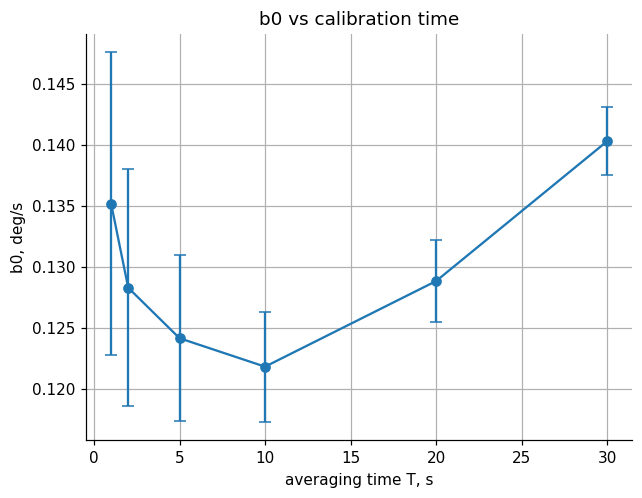

In [166]:
ts, ws = t[static], w[static] # starts at t=0

def mean_and_se(T): # mean of the first T seconds and its std err sigma/sqrt(N)
    x = ws[ts < T]
    return x.mean(), x.std(ddof=1) / np.sqrt(len(x))

b0, b0_se = mean_and_se(30)
print(f'b0 = {b0:.4f} deg/s  (standard error {b0_se:.5f}, N = {np.sum(ts < 30)})')

Ts = [1, 2, 5, 10, 20, 30] #, 35, 40, 50, 80, 90, 100, 150, 160]
b0_T, b0_T_se = np.array([mean_and_se(T) for T in Ts]).T
plt.errorbar(Ts, b0_T, yerr=b0_T_se, fmt='o-', capsize=4)
plt.xlabel('averaging time T, s');
plt.ylabel('b0, deg/s'); 
plt.title('b0 vs calibration time')
plt.show()

### calibration method

robot stands still, so mean of readings is the offset, median-based version ignores spikes:
1. take first `T_cal` seconds of the static log,
2. throw away samples further than 3 x MAD-sigma from the median (spikes),
3. average what is left

`T_cal` is where the curve above flattens

In [167]:
def calibrate_gyro(t_static, w_static, T_cal=10):
    x = w_static[t_static - t_static[0] < T_cal]    # first T_cal seconds of the given static samples
    med = np.median(x)
    sigma = 1.4826 * np.median(np.abs(x-med))
    keep = np.abs(x-med) <= 3 * sigma if sigma > 0 else np.ones_like(x, bool)
    return x[keep].mean()

T_CAL = 10
b0_own = calibrate_gyro(ts, ws, T_CAL)
print(f'calibrate_gyro(T_cal={T_CAL} s) = {b0_own:.4f} deg/s   (30 s mean: {b0:.4f})')
print('b0(T) =', dict(zip(Ts, np.round(b0_T, 4))))

# offset moves during the 3min (section 2), so on robot calibration should be done right before the run:
# last T_CAL seconds of the static phase; this value is used for the rotation run below
last = ts >= ts[-1] - T_CAL
b0_run = calibrate_gyro(ts[last], ws[last], T_CAL)
print(f'calibrate_gyro on the last {T_CAL}s before the run = {b0_run:.4f} deg/s')

calibrate_gyro(T_cal=10 s) = 0.1209 deg/s   (30 s mean: 0.1403)
b0(T) = {1: 0.1352, 2: 0.1283, 5: 0.1241, 10: 0.1218, 20: 0.1288, 30: 0.1403}
calibrate_gyro on the last 10s before the run = 0.1633 deg/s


## 2. Bias drift d

full static log is split into 30s windows; line through the window means has slope `d`
rate is integrated with the trapezoid rule on the real timestamps

window means, deg/s: [0.1403 0.1969 0.1924 0.1939 0.1891 0.1679]
d = 0.00665 deg/s per min
(a) uncorrected heading drift = 11.313 deg/min   (b0*60 = 8.417)
(b) heading error after 1 min with b0 removed: 1.729 deg
(b) heading error after 2 min with b0 removed: 4.890 deg
(b) heading error after 3 min with b0 removed: 7.176 deg
T_cal, s   b0, deg/s   error after 1 min, deg   error after 3 min, deg
     5      0.1224                   2.80                  10.38
    10      0.1209                   2.89                  10.65
    20      0.1279                   2.47                   9.40
    30      0.1403                   1.73                   7.17
    60      0.1687                   0.02                   2.08


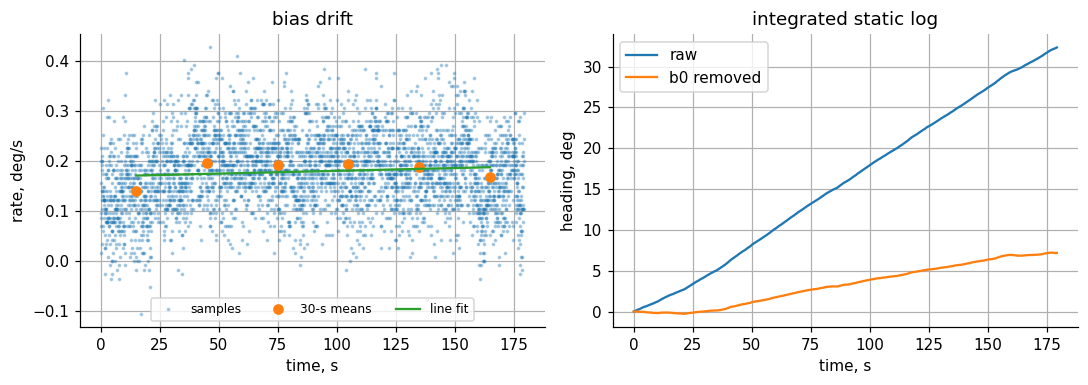

In [168]:
win = np.minimum(ts//30, 5) # window number 0..5 (180 s / 30 s)
win_mean = np.array([ws[win == k].mean() for k in range(6)])
win_t = 30 * np.arange(6) + 15                      # window centres, s
slope, icpt = np.polyfit(win_t, win_mean, 1)
d_drift = slope * 60                                # deg/s per min
print('window means, deg/s:', np.round(win_mean, 4))
print(f'd = {d_drift:.5f} deg/s per min')

th_raw = cumulative_trapezoid(ws, ts, initial=0)        # (a) uncorrected
th_res = cumulative_trapezoid(ws - b0, ts, initial=0)   # (b) bias removed
rate_raw = np.polyfit(ts, th_raw, 1)[0] * 60            # deg/min
print(f'(a) uncorrected heading drift = {rate_raw:.3f} deg/min   (b0*60 = {b0*60:.3f})')
for m in (1, 2, 3):
    print(f'(b) heading error after {m} min with b0 removed: {np.interp(60 * m, ts, th_res):.3f} deg')

# how much heading error does each calibration time leave over the whole 3-min static log? (first T s used, rest unseen)
print('T_cal, s   b0, deg/s   error after 1 min, deg   error after 3 min, deg')
for T in (5, 10, 20, 30, 60):
    b_T = calibrate_gyro(ts, ws, T)
    th_T = cumulative_trapezoid(ws - b_T, ts, initial=0)
    print(f'{T:6d}   {b_T:9.4f}   {np.interp(60, ts, th_T):20.2f}   {th_T[-1]:20.2f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(ts, ws, '.', ms=3, alpha=0.3, label='samples')
ax[0].plot(win_t, win_mean, 'o', label='30-s means')
ax[0].plot(win_t, slope * win_t + icpt, label='line fit')
ax[0].set(xlabel='time, s', ylabel='rate, deg/s', title='bias drift')
# ax[0].set_ylim(0.125, 0.225)
ax[0].legend(loc='lower center', ncol=3, fontsize=8)
ax[1].plot(ts, th_raw, label='raw')
ax[1].plot(ts, th_res, label='b0 removed')
ax[1].set(xlabel='time, s', ylabel='heading, deg', title='integrated static log')
ax[1].legend()
plt.tight_layout(); plt.show()

## 3. Measurement range

maximum and minimum rate in the rotation phases, gyro rate against encoder rate (flat top means saturation)

range: +286.7 / -286.4 deg/s
raw limits: 32764 / -32736
samples at the limit: 241 of 944 in the rotation run (25.5 %)
encoder rate in those samples: up to 391 / -448 deg/s


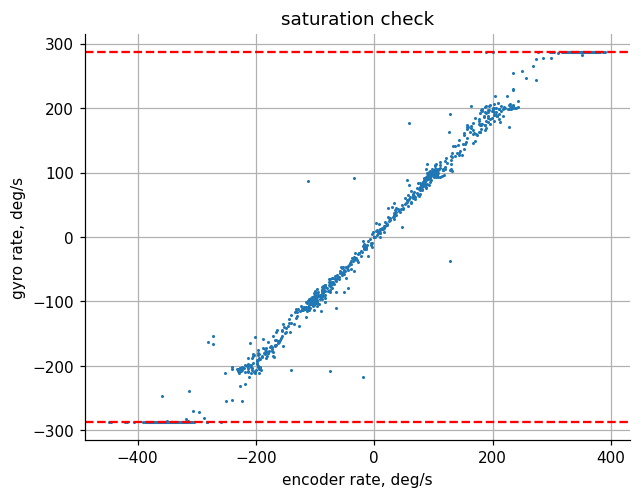

In [169]:
w_max, w_min = w[rot].max(), w[rot].min()
print(f'range: +{w_max:.1f} / {w_min:.1f} deg/s')
if has_raw:
    sat = np.abs(gz_raw) >= 32700                   # raw value at the end of the 16-bit range (32767)
    print(f'raw limits: {gz_raw[rot].max():.0f} / {gz_raw[rot].min():.0f}')
else:
    sat = rot & (np.abs(w) >= 0.99 * max(w_max, -w_min))
print(f'samples at the limit: {sat[rot].sum()} of {rot.sum()} in the rotation run ({100 * sat[rot].mean():.1f} %)')
if sat.any():
    print(f'encoder rate in those samples: up to {enc_rate[sat].max():.0f} / {enc_rate[sat].min():.0f} deg/s')

plt.plot(enc_rate[rot], w[rot], '.', ms=2)
plt.axhline(w_max, color='r', ls='--'); plt.axhline(w_min, color='r', ls='--')
# plt.axis('equal') 
plt.xlabel('encoder rate, deg/s'); plt.ylabel('gyro rate, deg/s'); plt.title('saturation check')
plt.show()

## 4. Resolution

Smallest non-zero step between distinct output values in the static log.

In [170]:
def resolution(values):                             # smallest gap between two distinct values
    return np.diff(np.unique(values)).min()

if has_raw:
    # gz_cal = raw value x factor, rounded to whole mdeg/s -> the step is exact in RAW units
    ok_k = rot & ~sat & (np.abs(gz_raw) > 50)
    k = np.median(gz_cal[ok_k] / gz_raw[ok_k])      # mdeg/s per raw unit
    step_raw = resolution(gz_raw[static])
    res_cal = step_raw * k / 1000
    print(f'raw values at rest: {len(np.unique(gz_raw[static]))}, smallest step {step_raw:.0f} raw unit(s)')
    print(f'raw -> factor k = {k:.4f} mdeg/s -> Delta = {step_raw:.0f} x {k/1000:.5f} = {res_cal:.5f} deg/s')
else:
    k = np.nan
    res_cal = resolution(gz_cal[rot]) / 1000        # sim gyro is noise-free at rest -> use the rotation run
    print(f'resolution (from gz_cal in the rotation run) = {res_cal} deg/s')

raw values at rest: 59, smallest step 1 raw unit(s)
raw -> factor k = 8.7495 mdeg/s -> Delta = 1 x 0.00875 = 0.00875 deg/s


## 5. Noise sigma

Standard deviation of the static log with b0 removed, histogram with a fitted Gaussian.

sigma = 0.0730 deg/s | R = sigma^2 = 0.005326 (deg/s)^2 at fs = 20 Hz
samples beyond 4 sigma: 0
mean of (rate - b0) over the whole static log: +0.0401 deg/s  (+0.55 sigma) -> the offset moved after the first 30 s


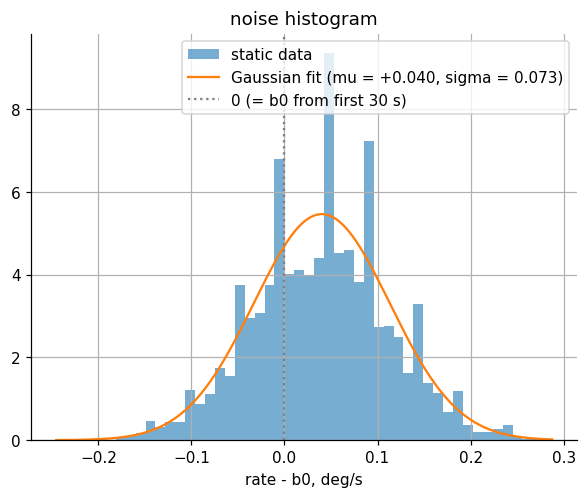

In [171]:
n_static = ws - b0
sigma = n_static.std(ddof=1)
R = sigma ** 2                                          # measurement noise variance given sample rate
print(f'sigma = {sigma:.4f} deg/s | R = sigma^2 = {R:.6f} (deg/s)^2 at fs = {fs:.0f} Hz')
outliers = np.sum(np.abs(n_static) > 4 * sigma) if sigma > 0 else 0
print(f'samples beyond 4 sigma: {outliers}')

mu = n_static.mean()
print(f'mean of (rate - b0) over the whole static log: {mu:+.4f} deg/s  ({mu / sigma:+.2f} sigma) -> the offset moved after the first 30 s')

plt.hist(n_static, bins=50, density=True, alpha=.6, label='static data')
if sigma > 0:
    xs = np.linspace(n_static.min(), n_static.max(), 200)
    plt.plot(xs, np.exp(-(xs-mu)**2 / (2*sigma**2)) / (sigma*np.sqrt(2*np.pi)), label=f'Gaussian fit (mu = {mu:+.3f}, sigma = {sigma:.3f})')
    plt.axvline(0, color='gray', ls=':', label='0 (= b0 from first 30 s)')
plt.xlabel('rate - b0, deg/s'); plt.legend(); plt.title('noise histogram'); plt.show()

## gyro angle against encoder angle

`theta_gyro = integral(w - b0)`, `theta_enc = r/W * (phi_R - phi_L)`. The offset `b0_run` comes from `calibrate_gyro` on the last seconds of the static phase, right before the run. Both angles start at 0 when the rotation starts.

table shows where `e(t)` grows: at rest only the offset acts; scale-factor error shows as a steady change of `e` in every block that scales with the turned angle; saturation shows as jump in the blocks with a large share at the limit; wheel slip would appear as steps in `e` at the hard `rect` reversals that are not at the limit.

final error: 28.65 deg   (theta_gyro = -173.1, theta_enc = -201.8)


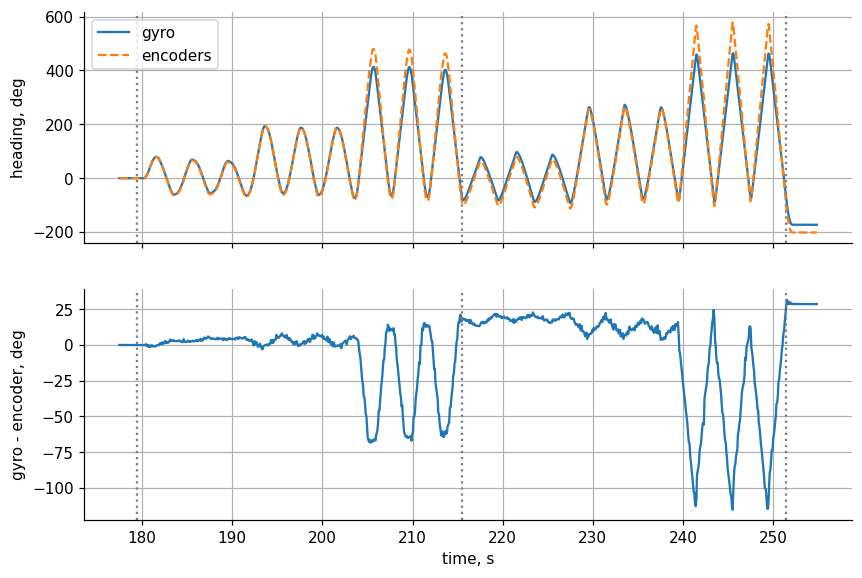

In [172]:
theta_gyro = cumulative_trapezoid(w - b0_run, t, initial=0)   # offset from the last seconds before the run
i_run = np.argmax(rot)                              # first sample of the rotation run
theta_gyro -= theta_gyro[i_run]                     # both headings start at 0 when the rotation starts
theta_enc -= theta_enc[i_run]
err = theta_gyro - theta_enc
print(f'final error: {err[-1]:.2f} deg   (theta_gyro = {theta_gyro[-1]:.1f}, theta_enc = {theta_enc[-1]:.1f})')

view = t >= t[i_run] - 2                            # rotation run only (static part is section 2)
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(t[view], theta_gyro[view], label='gyro')
ax[0].plot(t[view], theta_enc[view], '--', label='encoders')
ax[0].set_ylabel('heading, deg'); ax[0].legend()
ax[1].plot(t[view], err[view]); ax[1].set(xlabel='time, s', ylabel='gyro - encoder, deg')
for a in ax:
    for edge in (t[sin_][0], t[rect_][0], t[rest_][0]):   # phase borders
        a.axvline(edge, color='gray', ls=':')
plt.show()

block      change of e, deg   share at limit
sin  30 %         4.80          0.0 %
sin  60 %         0.25          0.0 %
sin 150 %         9.97         62.7 %
rect  30 %         3.20          0.0 %
rect  60 %        -3.07          0.0 %
rect 150 %        15.41         90.4 %


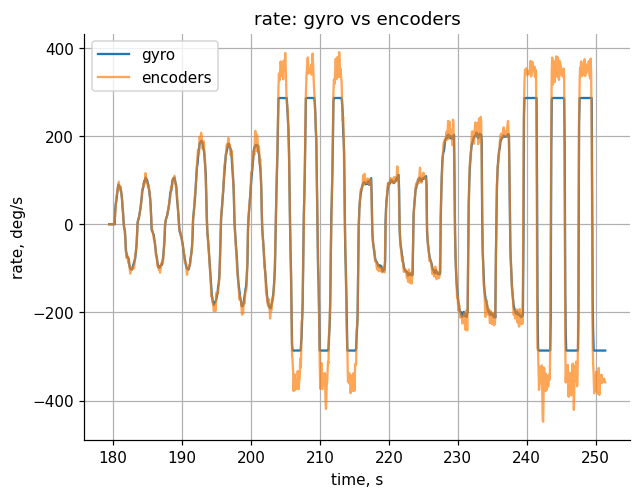

In [174]:
# where does e(t) grow? change of e in every 12 s block (one amplitude step) and share of samples at the gyro limit
print('block      change of e, deg   share at limit')
for ph, name in [(1, 'sin'), (2, 'rect')]:
    t_ph = t[phase == ph][0]
    for j, A in enumerate([30, 60, 150]):
        m = (phase == ph) & ((t - t_ph) // 12 == j)
        print(f'{name} {A:3d} %   {err[m][-1] - err[m][0]:10.2f}   {100 * sat[m].mean():10.1f} %')

plt.plot(t[rot], w[rot], label='gyro'); plt.plot(t[rot], enc_rate[rot], label='encoders', alpha=.7)
plt.xlabel('time, s'); plt.ylabel('rate, deg/s'); plt.legend(); plt.title('rate: gyro vs encoders'); plt.show()

## 6. Scale factor s, sign, raw -> deg/s

1. **Sign:** computed when the log is loaded. If the gyro reports positive for CW, it is multiplied by -1 so that both use the same convention.
2. **Raw -> deg/s:** the factor `k` from section 4 (only with the JS log).
3. **Scale-factor error:** least-squares slope of the gyro angle change against the encoder angle change over 0.1 s steps (line through the origin), CCW and CW separately. Slope = 1 + s.
   Steps within 0.1 s of a saturated sample are skipped (they would bend the line).

sign test (see load cell): the gyro reports positive for CCW; correlation 0.991
raw -> deg/s: 0.00875 deg/s per raw unit


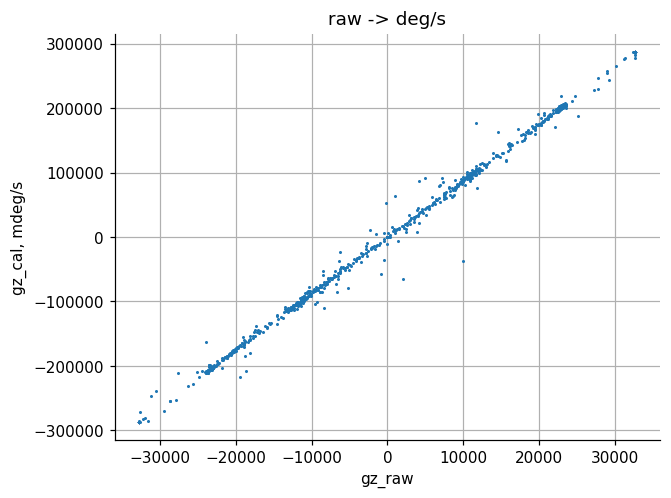

s (CCW) = -2.93 %    s (CW) = -2.73 %
  if r were 3.75 cm instead of 4.20 cm: s = +8.8 %
  if r were 4.00 cm instead of 4.20 cm: s = +2.0 %
  if r were 4.20 cm instead of 4.20 cm: s = -2.8 %
  if r were 4.50 cm instead of 4.20 cm: s = -9.3 %
  sin, A =  30 %: s =  -1.30 %   (149 samples)
  sin, A =  60 %: s =  -2.59 %   (157 samples)
  sin, A = 150 %: s =  -1.08 %   (32 samples)
  rect, A =  30 %: s =  -2.23 %   (158 samples)
  rect, A =  60 %: s =  -3.48 %   (148 samples)


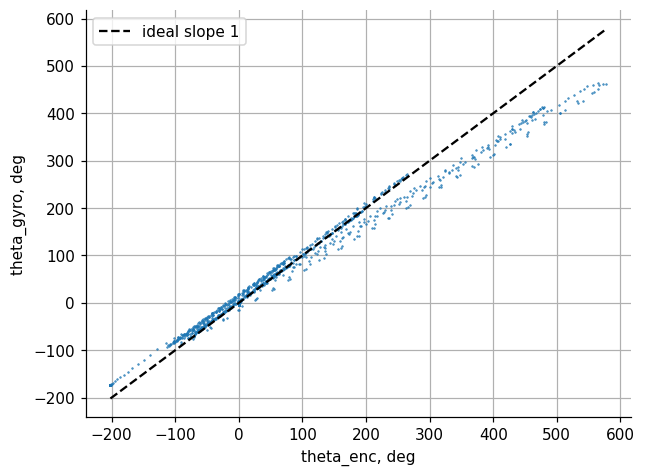

In [182]:
print(f'sign test (see load cell): the gyro reports positive for {direction}; correlation {corr:.3f}')

if has_raw:
    print(f'raw -> deg/s: {k/1000:.5f} deg/s per raw unit')
    plt.plot(gz_raw[rot], gz_cal[rot], '.', ms=2); plt.xlabel('gz_raw'); plt.ylabel('gz_cal, mdeg/s'); plt.title('raw -> deg/s'); plt.show()

step = max(2, int(0.1 * fs))                        # 0.1 s in samples
dg = theta_gyro[step:] - theta_gyro[:-step]         # gyro angle change over 0.1 s
de = theta_enc[step:] - theta_enc[:-step]           # encoder angle change over the same 0.1 s
near_sat = np.convolve(sat, np.ones(2 * step + 1), mode='same') > 0   # within 0.1 s of a saturated sample
ok = rot[:-step] & ~near_sat[:-step]
def scale_error(mask):                              # slope of a line through the origin, least squares
    slope = np.sum(dg[mask] * de[mask]) / np.sum(de[mask] ** 2)
    return (slope - 1) * 100                        # %
s_ccw = scale_error(ok & (de > 1))
s_cw = scale_error(ok & (de < -1))
print(f's (CCW) = {s_ccw:.2f} %    s (CW) = {s_cw:.2f} %')

# theta_enc is proportional to r, so 1 + s is proportional to 1/r: how much does s move if my r is a bit off?
s_mid = (s_ccw + s_cw) / 2
for r_alt in ((0.0375, 0.040, 0.042, 0.045) if RUN == 'real' else ()):
    print(f'  if r were {r_alt*100:.2f} cm instead of {r*100:.2f} cm: s = {((1 + s_mid / 100) * r / r_alt - 1) * 100:+.1f} %')

# does s depend on the amplitude? (12 s per amplitude step in both sin and rect)
tt, ph_step = t[:-step], phase[:-step]              # start time and phase of every 0.1 s step
for name, ph in [('sin', 1), ('rect', 2)]:
    t_ph = t[phase == ph][0]
    for j, A in enumerate([30, 60, 150]):
        m = ok & (ph_step == ph) & ((tt - t_ph) // 12 == j) & (np.abs(de) > 0.5)
        if m.sum() > 10:
            print(f'  {name}, A = {A:3d} %: s = {scale_error(m):6.2f} %   ({m.sum()} samples)')

plt.plot(theta_enc, theta_gyro, '.', ms=1); lim = [theta_enc.min(), theta_enc.max()]
plt.plot(lim, lim, 'k--', label='ideal slope 1'); plt.xlabel('theta_enc, deg'); plt.ylabel('theta_gyro, deg'); plt.legend(); plt.show()

## Simulated gyro

`gyro_sim(omega_true, t)` implements
`w_meas = Q_delta( sat_wmax( (1+s) * w_true + b0 + d*t + noise ) )`.
It is fed the rotation rate that the encoders measured and overlaid on the real log.

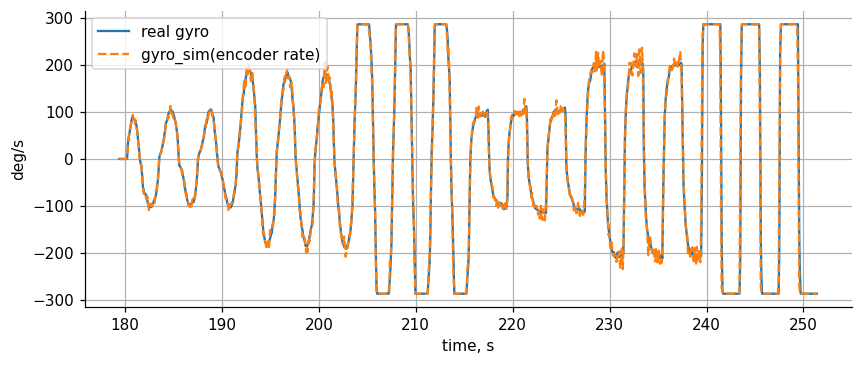

rms difference in rotation: 17.93 deg/s


In [179]:
rng = np.random.default_rng(0)

def gyro_sim(omega_true, t):                        # uses the measured parameters from sections 1-6
    s = np.where(omega_true >= 0, s_ccw, s_cw) / 100   # scale error, CCW / CW
    x = (1 + s) * omega_true + b0 + d_drift / 60 * t + rng.normal(0, sigma, len(t))
    x = np.clip(x, w_min, w_max)                    # saturation
    return np.round(x / res_cal) * res_cal          # quantisation

sim_out = gyro_sim(enc_rate, t)
plt.figure(figsize=(9, 3.5))
plt.plot(t[rot], w[rot], label='real gyro'); plt.plot(t[rot], sim_out[rot], '--', label='gyro_sim(encoder rate)')
plt.xlabel('time, s'); plt.ylabel('deg/s'); plt.legend(); plt.show()
print(f'rms difference in rotation: {np.sqrt(np.mean((sim_out[rot] - w[rot])**2)):.2f} deg/s')

## Parameter table

Datasheet column: ST L3GD20H (the TRIK gyro), set to the ±245 dps range. The measured raw -> deg/s factor (8.75 mdeg/s per unit) is the datasheet sensitivity for exactly this range.

In [180]:
table = pd.DataFrame([
    ['Offset (bias)',              'b0',            b0,           'deg/s',     f'static mean, T = 30 s (own method: {b0_own:.4f} first {T_CAL} s, {b0_run:.4f} last {T_CAL} s)',
                                                                                 '±25 typ. (zero-rate level, given for FS = 2000)'],
    ['Bias drift',                 'd',             d_drift,      'deg/s/min', '30-s window means', '±0.04 deg/s per °C'],
    ['Heading drift, uncorrected', '',              rate_raw,     'deg/min',   'slope of theta(t)', '-'],
    ['Measurement range',          '+wmax / -wmax', f'{w_max:.1f} / {w_min:.1f}', 'deg/s', 'saturation test',
                                                                                 '±245 nominal; 16-bit end: 32767 x 8.75 mdps = 286.7'],
    ['Resolution',                 'Delta',         res_cal,      'deg/s',     'quantisation step', '0.00875 (8.75 mdps/digit)'],
    ['Noise std',                  'sigma',         sigma,        'deg/s',     'static, 3 min', '0.011 deg/s/sqrt(Hz) -> ~0.078 at 50 Hz bandwidth'],
    ['Raw -> deg/s factor',        'k',             k / 1000,     'deg/s per unit', 'gz_cal vs gz_raw', '0.00875'],
    ['Scale-factor error CCW / CW','s',             f'{s_ccw:.2f} / {s_cw:.2f}', '%', 'gyro vs encoder angle', '±2 % over temperature, nonlinearity 0.2 % FS'],
    ['Positive rotation direction','',              direction,    '-',         'sign check', 'CCW'],
], columns=['Parameter', 'Symbol', 'Value', 'Unit', 'Method', 'Datasheet'])
table

,Parameter,Symbol,Value,Unit,Method,Datasheet
0,Offset (bias),b0,0.140275,deg/s,"static mean, T = 30 s (own method: 0.1209 firs...","±25 typ. (zero-rate level, given for FS = 2000)"
1,Bias drift,d,0.00665,deg/s/min,30-s window means,±0.04 deg/s per °C
2,"Heading drift, uncorrected",,11.312658,deg/min,slope of theta(t),-
3,Measurement range,+wmax / -wmax,286.7 / -286.4,deg/s,saturation test,±245 nominal; 16-bit end: 32767 x 8.75 mdps = ...
4,Resolution,Delta,0.008749,deg/s,quantisation step,0.00875 (8.75 mdps/digit)
5,Noise std,sigma,0.07298,deg/s,"static, 3 min",0.011 deg/s/sqrt(Hz) -> ~0.078 at 50 Hz bandwidth
6,Raw -> deg/s factor,k,0.008749,deg/s per unit,gz_cal vs gz_raw,0.00875
7,Scale-factor error CCW / CW,s,-2.93 / -2.73,%,gyro vs encoder angle,"±2 % over temperature, nonlinearity 0.2 % FS"
8,Positive rotation direction,,CCW,-,sign check,CCW


## Which error dominates, and what the calibration leaves

Rough heading-error budget after `t` seconds of driving, using the numbers above:

- uncorrected bias: `b0 * t`
- residual bias after `calibrate_gyro` (drift only): `d * t^2 / 2`
- noise (random walk): `sigma * sqrt(dt * t)`
- scale factor: `|s| * angle turned` (angle turned scaled to the first `t` seconds of the rotation run)

In [184]:
dt = 1 / fs
turned = np.sum(np.abs(np.diff(theta_enc)))         # total angle turned in the run, deg
s_abs = max(abs(s_ccw), abs(s_cw)) / 100
rows = []
for sec in (10, 60, 180):
    rows.append([sec, abs(b0) * sec, abs(d_drift / 60) * sec**2 / 2, sigma * np.sqrt(dt * sec), s_abs * turned * min(sec / 72, 1)])
budget = pd.DataFrame(rows, columns=['t, s', 'bias (uncorrected), deg', 'bias drift (after calibration), deg', 'noise, deg', 'scale factor, deg'])
display(budget.round(3))
left = cumulative_trapezoid(ws - b0_own, ts, initial=0)[-1]
print(f'calibrate_gyro needs {T_CAL} s of standing still; heading error left after 3 min static: {left:.3f} deg')

,"t, s","bias (uncorrected), deg","bias drift (after calibration), deg","noise, deg","scale factor, deg"
0,10,1.403,0.006,0.052,52.683
1,60,8.417,0.200,0.128,316.100
2,180,25.250,1.796,0.222,379.320


calibrate_gyro needs 10 s of standing still; heading error left after 3 min static: 10.647 deg


## Conclusion

**Parameters vs datasheet (ST L3GD20H, ±245 dps range)**
- Conversion factor 8.75 mdeg/s per raw unit and resolution Δ = 1 raw unit = 0.00875 deg/s: exactly the datasheet sensitivity, so the gyro runs in the ±245 dps range.
- Range ±286.7 deg/s: the end of the 16-bit output (32767 × 8.75 mdeg/s), a bit above the nominal ±245 dps. At 150 % power the wheels turned the robot at up to ~400 deg/s, so 25 % of the rotation samples were clipped.
- Noise σ = 0.073 deg/s: close to the datasheet value 0.011 deg/s/√Hz × √50 Hz ≈ 0.078 deg/s. σ is the noise of one sample; logging at 20 Hz only picks samples, it does not average them.
- Offset b0 = 0.14 deg/s (first 30 s): far inside the datasheet's typical ±25 dps zero-rate level. Uncorrected, it turns into 11 deg/min of heading drift, so it must be removed.
- Positive output for CCW rotation, as the datasheet says, and the same convention as the encoders.

**Drift and calibration**
- The offset was not constant: it rose from 0.14 to ~0.19 deg/s in the first ~40 s and then stayed nearly flat (fitted d = 0.007 deg/s per min). This looks like thermal settling: the datasheet gives up to 0.04 deg/s per °C.
- `calibrate_gyro` (median, 3σ spike rejection, mean) needs the robot to stand still. With 10 s it left 2.9° after 1 min and 10.7° after 3 min, because those 10 s were taken while the offset was still settling. With 60 s it left 0.0° and 2.1°. Conclusion: calibrate right before driving, after the warm-up, not at power-on. That is why the rotation run uses `b0_run` from the last 10 s.

**Gyro vs encoder heading**
- The two headings have the same shape and size (rate correlation 0.99). The final difference is 29°.
- Most of it (≈ 25°) appears in the two 150 % blocks, where the gyro is at its limit: this is saturation. In the 30 % and 60 % blocks, e changes by only a few degrees.
- Scale factor s ≈ −2.8 % (CCW −2.9 %, CW −2.7 %). It moves by about the same amount as any error in the assumed wheel radius (r = 4.0 cm instead of 4.2 cm gives +2 %). The datasheet allows ±2 % sensitivity change over temperature. So s cannot be split between the gyro and the wheel geometry.
- No floor-mark reference was measured. Without one, the remaining gyro-encoder difference cannot be assigned to one sensor.

**Which error dominates (budget table)**
- Uncalibrated: the offset (1.4° after 10 s, 25° after 3 min).
- After calibration: for a turning robot, the scale factor (proportional to the angle turned); for a standing robot, the offset drift over minutes. Noise is never the main term (0.2° after 3 min).

**Limitations**
- 20 samples/s instead of 100 Hz: the logger loop reads the gyro, the raw gyro and two encoders every pass.